# SupportAI — Classification d'intentions : comparaison de modèles
**Étudiant 3 — NLP & ML** · NovaShop · 14 intentions officielles (`data/annotations/intents.csv`)

Objectifs : définir les intentions, comparer **TF-IDF + Régression Logistique**, **Linear SVM** et une approche **embeddings**, puis analyser les erreurs.

⚠️ **Lecture honnête des scores.** Les données d'entraînement sont générées par gabarits (synthétiques, FR/EN/darija). Un split aléatoire donnerait des scores gonflés (quasi-doublons). Nous utilisons donc :
1. une **validation croisée groupée par gabarit** (`GroupKFold`) pour la sélection de modèle ;
2. un **jeu de test manuel indépendant** (140 phrases rédigées à part, 0 doublon exact avec le train) ;
3. le **pilot 20** annoté par l'équipe (`data/annotations/`), seule donnée « réelle » disponible pour l'instant (20 phrases : 1 erreur = 5 points) pour la généralisation.

In [1]:
import os, sys, json, warnings
if os.path.basename(os.getcwd()) == 'notebooks': os.chdir('..')
sys.path.insert(0, os.getcwd())
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from intent_clf.nlp_core import *
train, test = load_data()
pipes, backend = make_pipelines()
print('Embedding backend:', backend)
print(train.shape, test.shape)

Could not resolve the revision of 'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2' (403 Forbidden (agent proxy: no rule or network setting allows this host)). Loading without pinning to a single commit.


Embedding backend: lsa
(895, 4) (140, 3)


## 1. Intentions et données

In [2]:
intents = json.load(open('data/intents.json'))['intents']
pd.DataFrame([{'intent':k,'route (proposée)':v['route'],'needs_order_id':v['needs_order_id']} for k,v in intents.items()])

,intent,route (proposée),needs_order_id
0,order_tracking,order_api,True
1,order_change_cancel,order_api,True
2,delivery_issue,order_api,True
3,return_request,rag,False
4,refund_status,order_api,True
5,payment_info,rag,False
6,payment_issue,human_handoff,True
7,technical_support,rag,False
8,warranty_claim,rag,False
9,product_info,rag,False


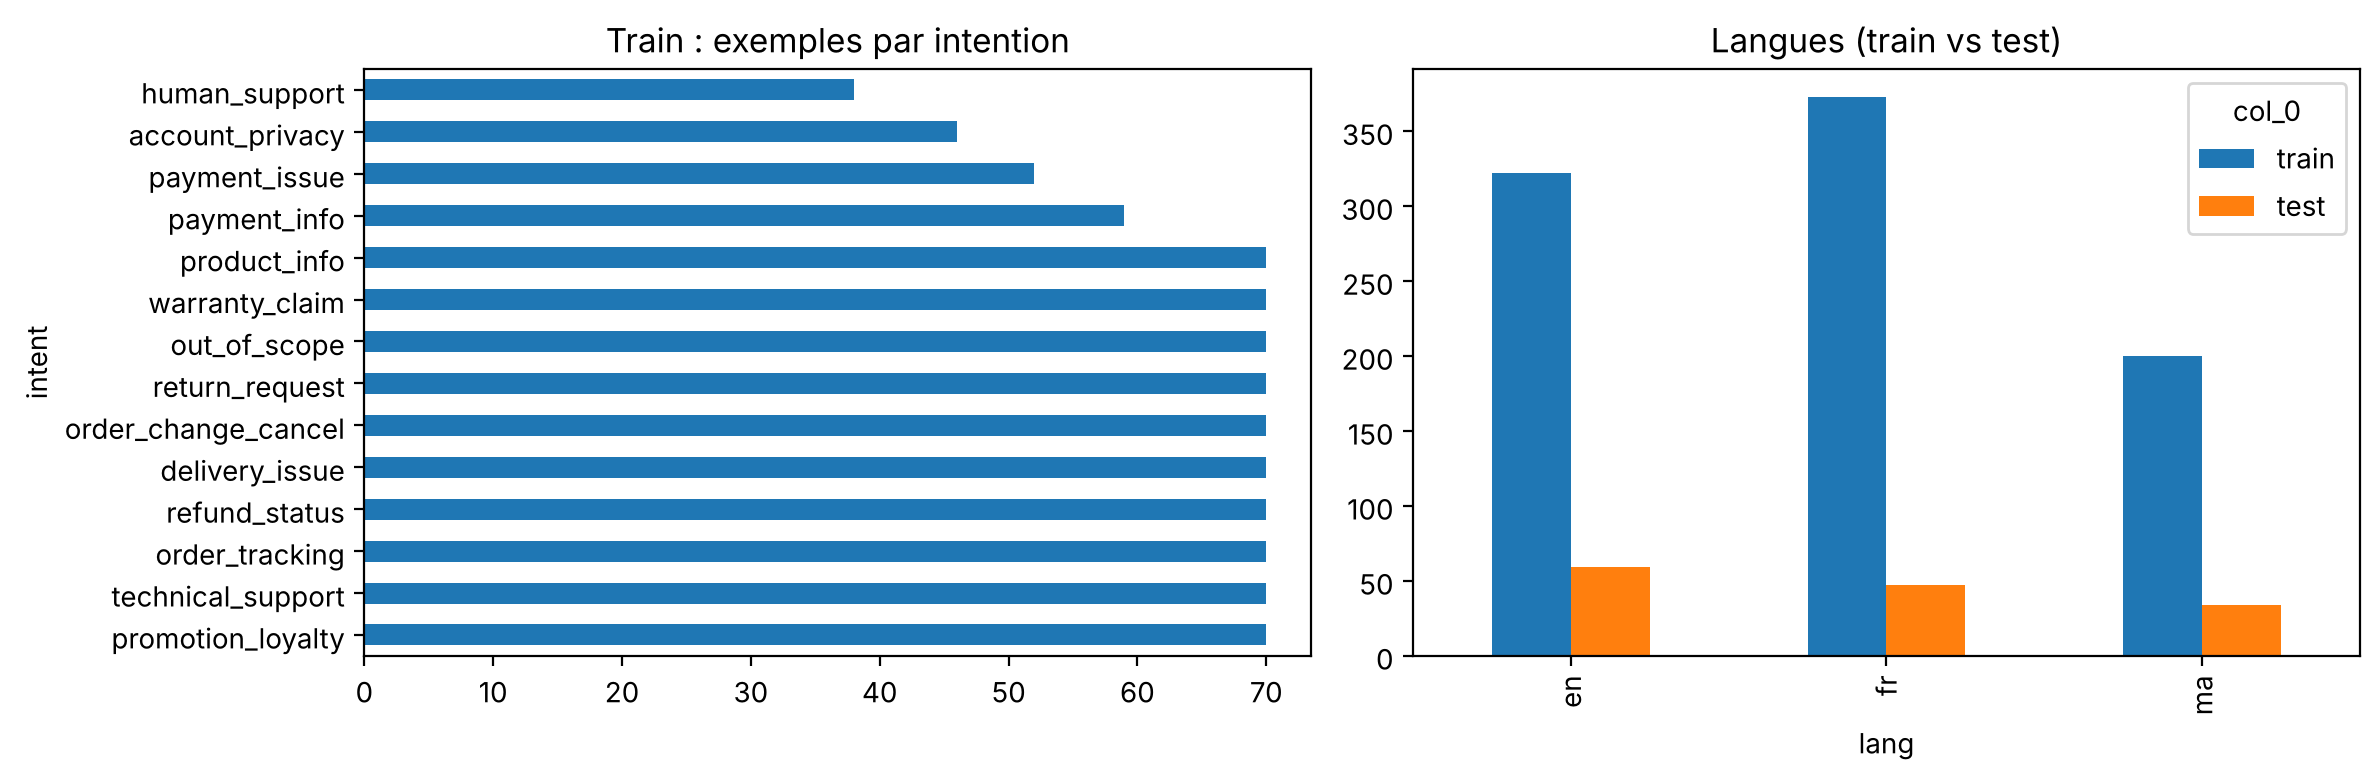

In [3]:
fig, ax = plt.subplots(1,2, figsize=(12,4))
train.intent.value_counts().plot.barh(ax=ax[0], title='Train : exemples par intention')
pd.crosstab(train.lang, 'train').join(pd.crosstab(test.lang, 'test')).plot.bar(ax=ax[1], title='Langues (train vs test)')
plt.tight_layout(); plt.show()

## 2. Entraînement et comparaison

In [4]:
rows, preds = [], {}
for name, pipe in pipes.items():
    oof = cv_predict(pipe, train)
    pipe.fit(train.text, train.intent)
    preds[name] = pipe.predict(test.text)
    cv, te = metrics(train.intent, oof), metrics(test.intent, preds[name])
    rows.append({'model':name, **{f'CV_{k}':v for k,v in cv.items() if k!='f1_weighted'},
                 **{f'TEST_{k}':v for k,v in te.items() if k!='f1_weighted'}})
res = pd.DataFrame(rows).set_index('model').round(3)
res

,CV_accuracy,CV_precision_macro,CV_recall_macro,CV_f1_macro,TEST_accuracy,TEST_precision_macro,TEST_recall_macro,TEST_f1_macro
model,,,,,,,,
tfidf_lr,0.686,0.722,0.697,0.701,0.836,0.852,0.836,0.834
tfidf_svm,0.723,0.743,0.736,0.733,0.843,0.857,0.843,0.842
embed_lr,0.697,0.718,0.709,0.708,0.771,0.800,0.771,0.776


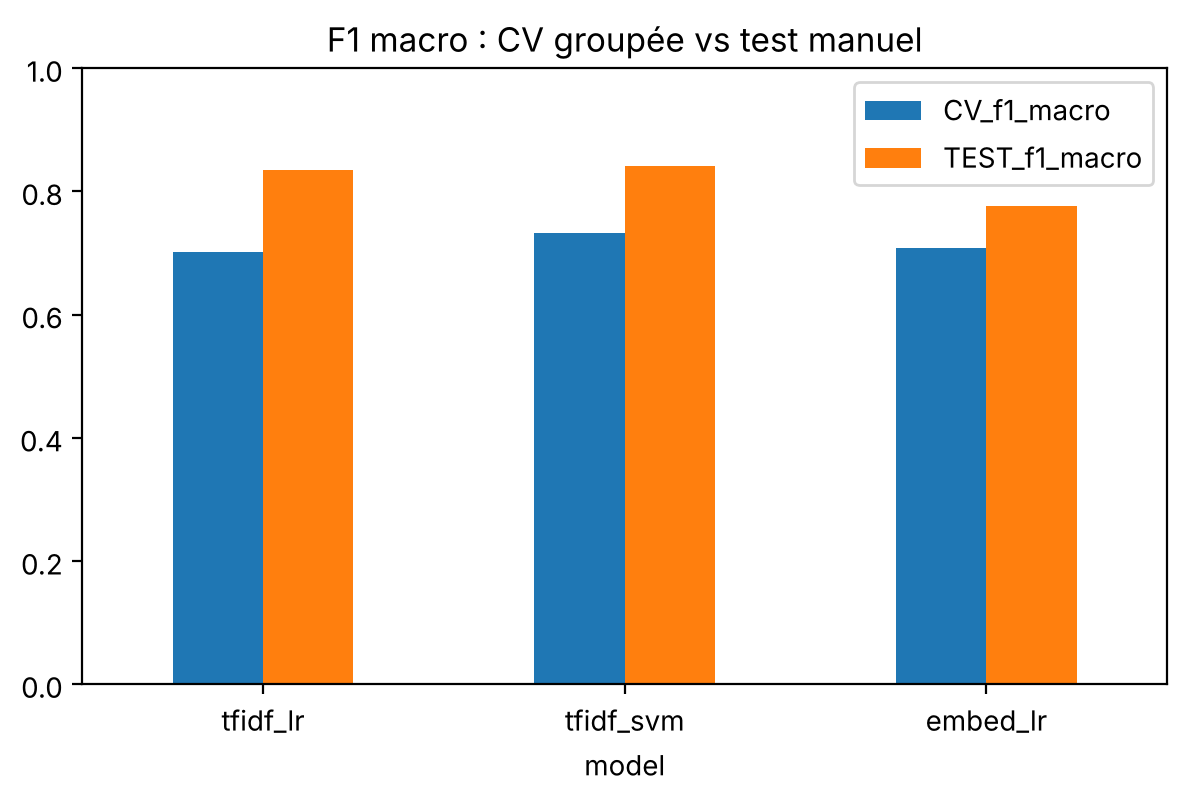

In [5]:
res[['CV_f1_macro','TEST_f1_macro']].plot.bar(figsize=(7,4), ylim=(0,1), title='F1 macro : CV groupée vs test manuel')
plt.xticks(rotation=0); plt.show()

In [6]:
pilot = load_pilot()
if pilot is None:
    print('Pilot 20 absent')
else:
    pp = pipes[best_name := res['CV_f1_macro'].idxmax()].predict(pilot.text)
    print(f"{best_name} sur le pilot 20 : accuracy = {(pp==pilot.intent).mean():.2f} ({(pp!=pilot.intent).sum()} erreur(s) / {len(pilot)})")
    display(pilot.assign(pred=pp)[pp != pilot.intent][['id','text','intent','pred','ambiguous_oui_non']])

tfidf_svm sur le pilot 20 : accuracy = 0.95 (1 erreur(s) / 20)


,id,text,intent,pred,ambiguous_oui_non
7,INT-0008,j'ai renvoyé mon colis il y a 3 semaines et je...,refund_status,delivery_issue,non


**Lecture.** Le Linear SVM sur TF-IDF (mots + caractères) est le meilleur modèle sur la CV groupée et sur le test manuel (à confirmer sur vos données réelles). Les n-grammes de caractères aident sur l'orthographe variable et le darija translittéré.

> Le backend d'embeddings utilisé ici est indiqué plus haut. Si `lsa`, il s'agit d'un **repli hors-ligne** (LSA = SVD sur TF-IDF caractères) car le modèle pré-entraîné multilingue n'était pas téléchargeable dans cet environnement : ce n'est *pas* un vrai embedding sémantique. Relancer sur une machine avec accès à Hugging Face pour obtenir le vrai résultat `sbert` (aucun changement de code).

## 3. Détail par intention (meilleur modèle)

In [7]:
best = res['CV_f1_macro'].idxmax(); print('Meilleur (CV) :', best)
print(classification_report(test.intent, preds[best], zero_division=0))

Meilleur (CV) : tfidf_svm
                     precision    recall  f1-score   support

    account_privacy       0.83      1.00      0.91        10
     delivery_issue       0.69      0.90      0.78        10
      human_support       1.00      0.80      0.89        10
order_change_cancel       0.90      0.90      0.90        10
     order_tracking       0.75      0.60      0.67        10
       out_of_scope       1.00      0.90      0.95        10
       payment_info       0.75      0.90      0.82        10
      payment_issue       0.75      0.90      0.82        10
       product_info       0.82      0.90      0.86        10
  promotion_loyalty       0.86      0.60      0.71        10
      refund_status       1.00      0.70      0.82        10
     return_request       0.75      0.90      0.82        10
  technical_support       0.90      0.90      0.90        10
     warranty_claim       1.00      0.90      0.95        10

           accuracy                           0.84       

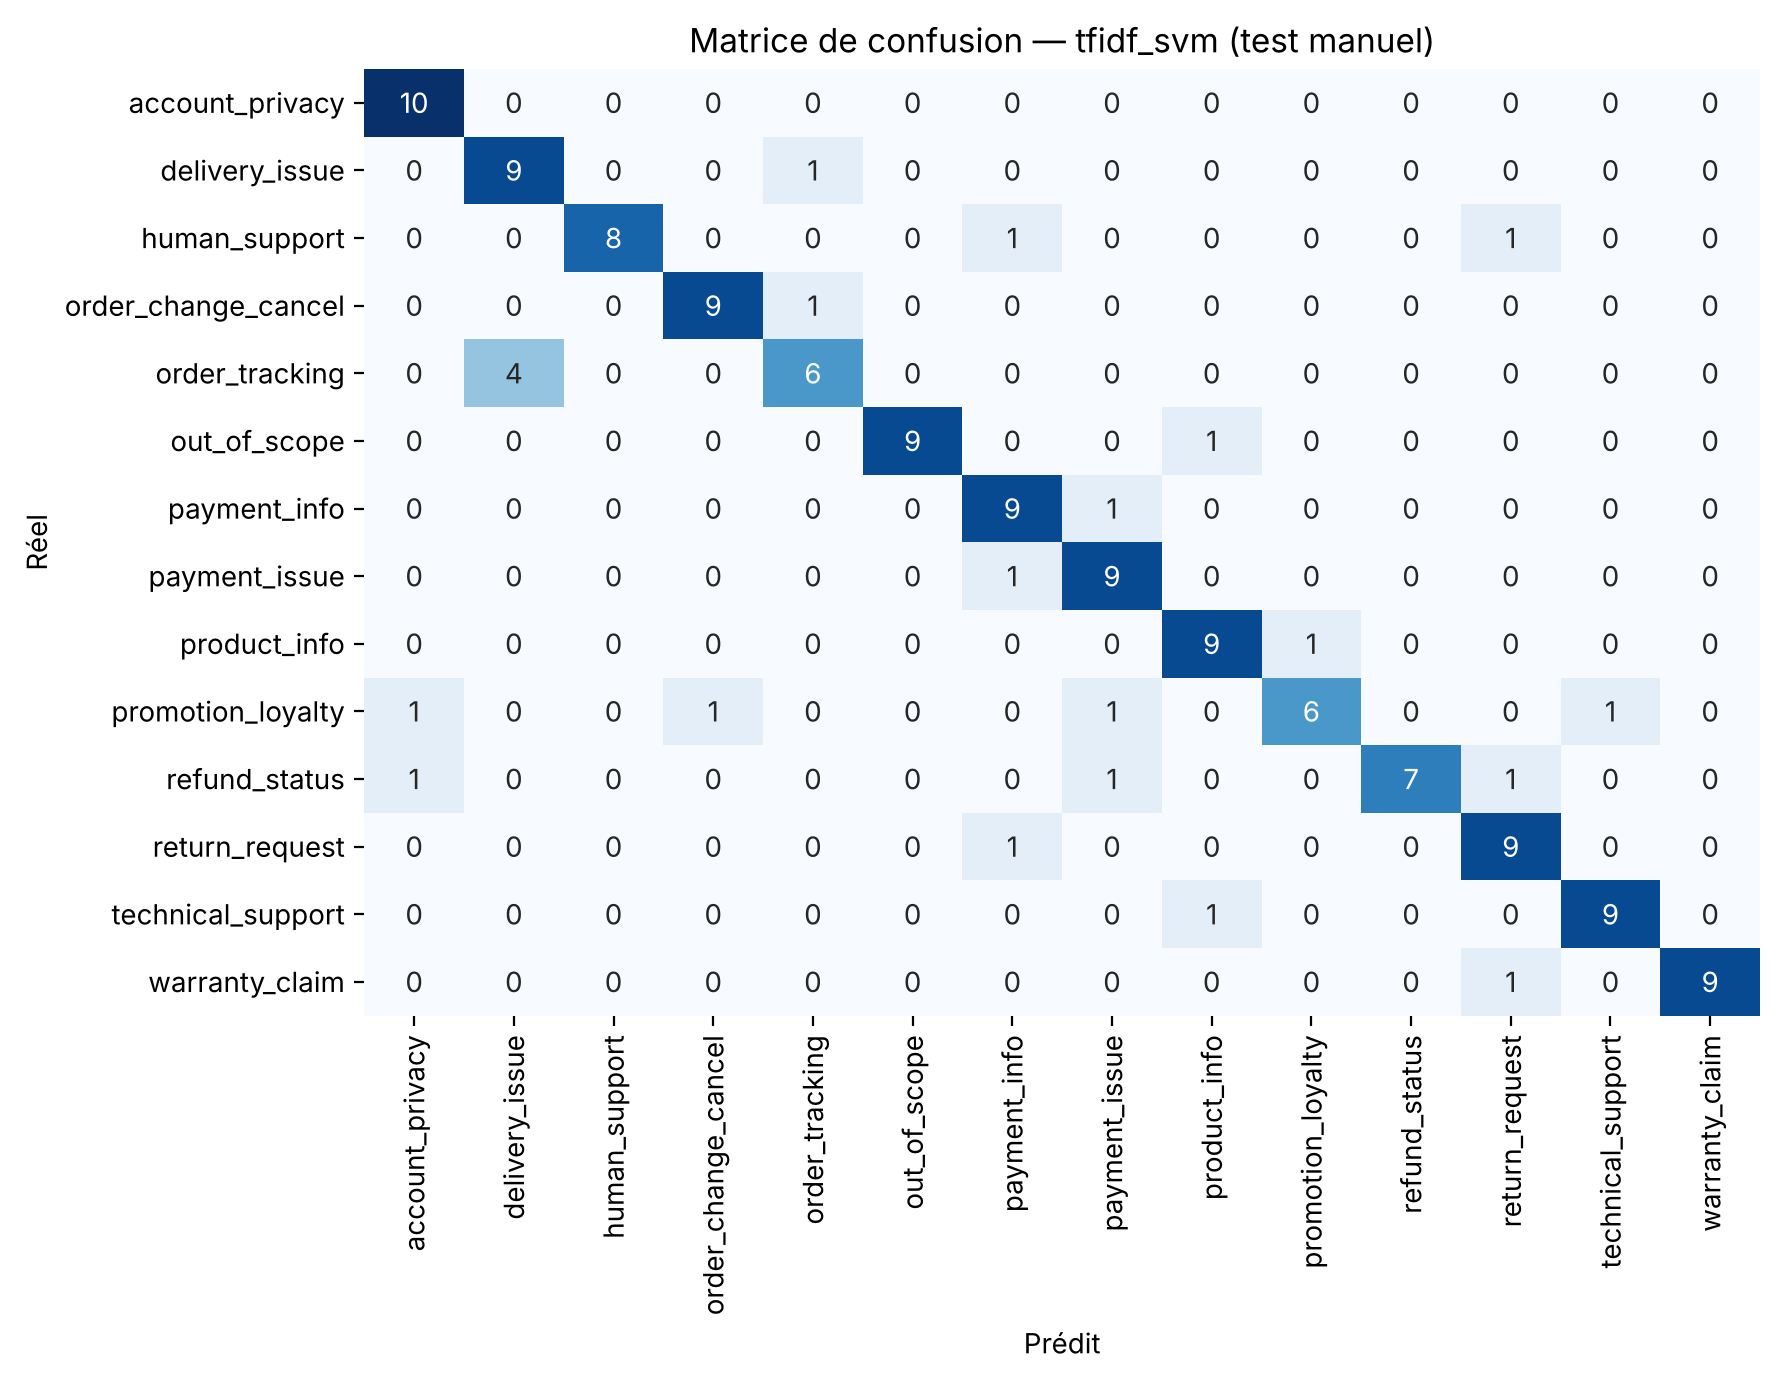

In [8]:
labels = sorted(train.intent.unique())
cm = confusion_matrix(test.intent, preds[best], labels=labels)
plt.figure(figsize=(9,7)); sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, cbar=False)
plt.xlabel('Prédit'); plt.ylabel('Réel'); plt.title(f'Matrice de confusion — {best} (test manuel)'); plt.tight_layout()
plt.savefig('reports/confusion_matrix_best.png', dpi=130); plt.show()

## 4. Analyse d'erreurs

In [9]:
err = test.assign(pred=preds[best])[lambda d: d.pred != d.intent]
print(f'{len(err)} erreurs / {len(test)}')
print(err.groupby(['intent','pred']).size().sort_values(ascending=False).head(10).to_string())
err[['text','intent','pred','lang']].to_string(max_colwidth=70)

22 erreurs / 140
intent               pred             
order_tracking       delivery_issue       4
human_support        payment_info         1
delivery_issue       order_tracking       1
human_support        return_request       1
order_change_cancel  order_tracking       1
out_of_scope         product_info         1
payment_info         payment_issue        1
payment_issue        payment_info         1
product_info         promotion_loyalty    1
promotion_loyalty    account_privacy      1


"                                                                      text               intent                 pred lang\n1                        Bonjour, j'aimerais savoir où se trouve mon colis       order_tracking       delivery_issue   fr\n3                                        When does my laptop get delivered       order_tracking       delivery_issue   en\n6                              How do I know where my package currently is       order_tracking       delivery_issue   en\n7                                    Wach n9der nchouf fin wsl colis dyali       order_tracking       delivery_issue   ma\n16                               How do I stop my order from being shipped  order_change_cancel       order_tracking   en\n21                        Delivery delayed, what's going on with my order?       delivery_issue       order_tracking   en\n35                        Can I swap my headphones for a different colour?       return_request         payment_info   en\n40   I returned

In [10]:
acc_lang = test.assign(ok=preds[best]==test.intent).groupby('lang').ok.agg(['mean','count']).round(3)
acc_lang

,mean,count
lang,,
en,0.763,59
fr,0.894,47
ma,0.912,34


**Constats (sur ce run : SVM, 22 erreurs / 140 sur le test manuel)**
- **Frontière `order_tracking` ↔ `delivery_issue`** : 4 « où est mon colis » sont prédits `delivery_issue` (et un retard prédit `order_tracking`). C'est exactement la `boundary_rule` des guidelines (« information sans problème » vs « incident »). Des signaux comme « où se trouve », « when does… get delivered » apparaissent aussi dans les phrases de retard : le modèle lexical a du mal ; il faudra plus d'exemples contrastés annotés par l'équipe.
- **`refund_status`** : « l'argent revient sur ma carte » est confondu avec `payment_issue` / `account_privacy` (vocabulaire jamais vu).
- **`promotion_loyalty`** : les codes/coupons formulés autrement (« coupon », « voucher ») sont mal reconnus ; le cas « code BLACK20 refusé au paiement » est volontairement à la frontière `payment_issue` (la règle des guidelines dit promo).
- **`human_support`** est la classe avec le moins de données (38 exemples) → plusieurs formulations sont ratées.
- Le pilot 20 donne un meilleur score que le test manuel, mais il est petit et ses phrases sont proches des exemples des guidelines : ne pas le surinterpréter.
- Comparer la performance par langue (cellule ci-dessus) pour mesurer l'impact du darija translittéré.

## 5. Seuil de confiance (rejet des cas douteux)

In [11]:
P = predict_proba_any(pipes[best], test.text)
conf, ok = P.max(1), (pipes[best].classes_[P.argmax(1)] == test.intent.values)
rows=[]
for t in [0.0,0.2,0.3,0.4,0.5,0.6]:
    keep = conf>=t
    rows.append({'seuil':t,'couverture':keep.mean().round(3),'accuracy_sur_acceptés':ok[keep].mean().round(3)})
pd.DataFrame(rows)

,seuil,couverture,accuracy_sur_acceptés
0,0.0,1.000,0.843
1,0.2,0.979,0.854
2,0.3,0.871,0.885
3,0.4,0.757,0.925
4,0.5,0.650,0.923
5,0.6,0.557,0.949


Compromis couverture / précision : un seuil plus haut envoie plus de messages vers le *fallback* / conseiller humain mais fiabilise les réponses automatiques. Le seuil par défaut de l'API (`models/config.json`) est calculé sur la CV, **pas** sur ce test.

Note : les scores du SVM sont un softmax de `decision_function` (non calibré) — à interpréter comme un score relatif, pas une vraie probabilité.

## 6. Test rapide de l'inférence

In [12]:
from intent_clf.inference import classify
for q in ["Où est ma commande ORD204 ?", "Do you accept PayPal?", "Quel temps demain ?", "bghit nhdr m3a chi wa7d"]:
    r = classify(q); print(f"{q!r:40} -> {r['intent']:26} {r['confidence']:.2f} route={r['route']}")

'Où est ma commande ORD204 ?'            -> order_tracking             0.96 route=order_api
'Do you accept PayPal?'                  -> payment_info               0.94 route=rag
'Quel temps demain ?'                    -> out_of_scope               0.79 route=fallback
'bghit nhdr m3a chi wa7d'                -> human_support              0.97 route=human_handoff
